K-Means Clustering Result:
     SALES  QUANTITYORDERED  KMeans_Cluster
0  2871.00               30               2
1  2765.90               34               2
2  3884.34               41               1
3  3746.70               45               1
4  5205.27               49               1


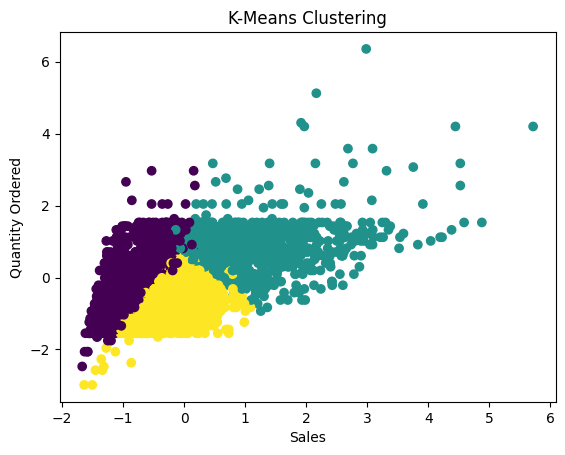


Hierarchical Clustering Result:
     SALES  QUANTITYORDERED  Hierarchical_Cluster
0  2871.00               30                     2
1  2765.90               34                     2
2  3884.34               41                     0
3  3746.70               45                     0
4  5205.27               49                     1

Cluster Count:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


In [4]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

# Step 1: Load dataset
data = pd.read_csv("sales_data_sample.csv", encoding="latin1")

# Step 2: Select numerical columns
X = data[['SALES', 'QUANTITYORDERED', 'PRICEEACH', 'MSRP']]

# Step 3: Scale the data
sc = StandardScaler()
X = sc.fit_transform(X)

# Step 4: Apply K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data['KMeans_Cluster'] = kmeans.fit_predict(X)

# Step 5: Display K-Means result
print("K-Means Clustering Result:")
print(data[['SALES', 'QUANTITYORDERED', 'KMeans_Cluster']].head())

# Step 6: Plot K-Means graph
plt.scatter(X[:, 0], X[:, 1], c=data['KMeans_Cluster'])
plt.title("K-Means Clustering")
plt.xlabel("Sales")
plt.ylabel("Quantity Ordered")
plt.show()

# Step 7: Apply Hierarchical Clustering
hc = AgglomerativeClustering(n_clusters=3)
data['Hierarchical_Cluster'] = hc.fit_predict(X)

# Step 8: Display Hierarchical result
print("\nHierarchical Clustering Result:")
print(data[['SALES', 'QUANTITYORDERED', 'Hierarchical_Cluster']].head())

print("\nCluster Count:")
print(data['Hierarchical_Cluster'].value_counts())


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Step 1: Load dataset
data = pd.read_csv("sales_data_sample.csv", encoding="latin1")

In [4]:
# Step 2: Select numerical columns
X = data[['SALES', 'QUANTITYORDERED', 'PRICEEACH', 'MSRP']]

# Step 3: Scale the data
sc = StandardScaler()
X = sc.fit_transform(X)
data.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
# Step 4: Find optimal number of clusters
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)


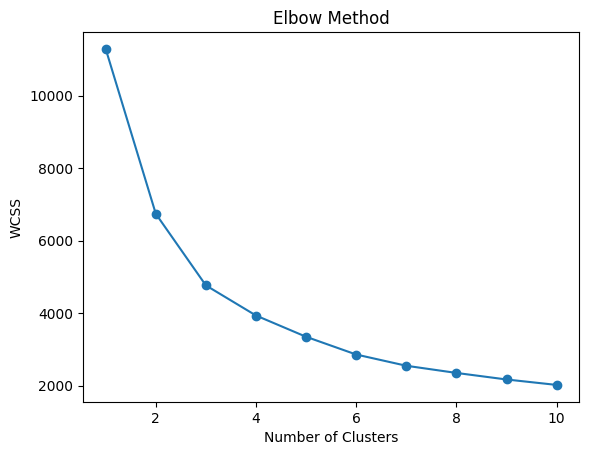

     SALES  QUANTITYORDERED  Cluster
0  2871.00               30        2
1  2765.90               34        2
2  3884.34               41        1
3  3746.70               45        1
4  5205.27               49        1

Cluster Count:
Cluster
2    996
0    975
1    852
Name: count, dtype: int64


In [4]:

# Step 5: Plot Elbow graph
plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

# Step 6: Apply K-Means with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data['Cluster'] = kmeans.fit_predict(X)

# Step 7: Display result
print(data[['SALES', 'QUANTITYORDERED', 'Cluster']].head())
print("\nCluster Count:")
print(data['Cluster'].value_counts())


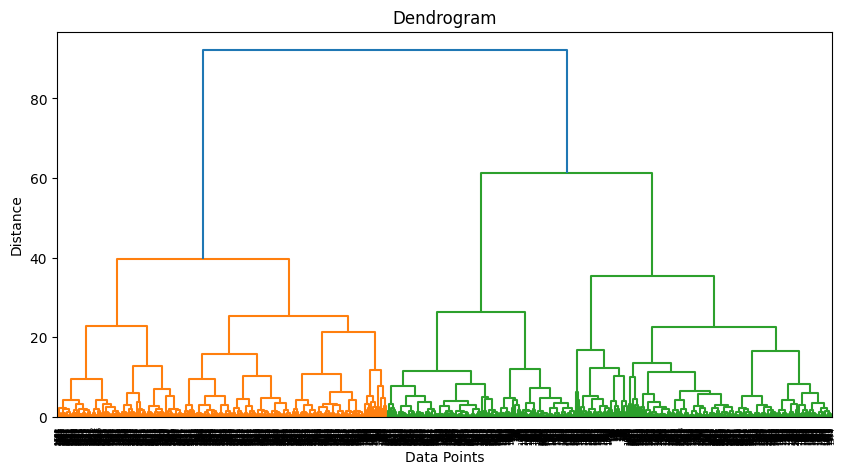

In [7]:
Z = linkage(X, method='ward')

plt.figure(figsize=(10, 5))
dendrogram(Z)

plt.title("Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

In [8]:
#apply hierarchical clustering with 3 clusters
clusters = fcluster(Z, 3, criterion='maxclust')

data['Cluster'] = clusters

In [9]:
print(data[['SALES', 'QUANTITYORDERED', 'Cluster']].head())

print("\nCluster Count:")
print(data['Cluster'].value_counts())

     SALES  QUANTITYORDERED  Cluster
0  2871.00               30        2
1  2765.90               34        2
2  3884.34               41        1
3  3746.70               45        1
4  5205.27               49        3

Cluster Count:
Cluster
1    1204
3     934
2     685
Name: count, dtype: int64
